<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-08A-Pretrained-Faster-RCNN/DL_Tutorial_8A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

from torchvision.transforms import functional as F
from torchvision.utils import draw_bounding_boxes
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Device: cuda


In [2]:
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(
    weights=weights
).to(device)

model.eval()

class_names = weights.meta["categories"]

print("Pretrained Faster R-CNN loaded successfully!")
print("Number of category entries:", len(class_names))
print("Model backbone: ResNet50 + FPN")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 176MB/s]


Pretrained Faster R-CNN loaded successfully!
Number of category entries: 91
Model backbone: ResNet50 + FPN


In [3]:
def detect_objects(image, model, threshold=0.5):

    model.eval()

    # Convert PIL image to PyTorch tensor
    image_tensor = F.to_tensor(image).to(device)

    # Run inference
    with torch.no_grad():
        predictions = model([image_tensor])[0]

    # Move results to CPU
    boxes = predictions["boxes"].cpu()
    labels = predictions["labels"].cpu()
    scores = predictions["scores"].cpu()

    # Filter low-confidence predictions
    keep = scores >= threshold

    return {
        "boxes": boxes[keep],
        "labels": labels[keep],
        "scores": scores[keep]
    }

In [4]:
def display_detections(image, predictions, class_names):

    image_tensor = F.pil_to_tensor(image)

    boxes = predictions["boxes"]
    labels = predictions["labels"]
    scores = predictions["scores"]

    print("Objects detected:", len(boxes))

    if len(boxes) == 0:
        plt.figure(figsize=(10, 7))
        plt.imshow(image)
        plt.title("No objects detected above threshold")
        plt.axis("off")
        plt.show()
        return

    text_labels = []

    for label, score in zip(labels, scores):

        class_name = class_names[label.item()]

        text_labels.append(
            f"{class_name}: {score.item():.2f}"
        )

    annotated_image = draw_bounding_boxes(
        image_tensor,
        boxes,
        labels=text_labels,
        colors="red",
        width=3
    )

    plt.figure(figsize=(12, 8))
    plt.imshow(F.to_pil_image(annotated_image))
    plt.title("Pretrained Faster R-CNN Object Detection")
    plt.axis("off")
    plt.show()

Saving Picture_blueBG.jpeg to Picture_blueBG.jpeg
Uploaded image: Picture_blueBG.jpeg
Image dimensions: (660, 851)


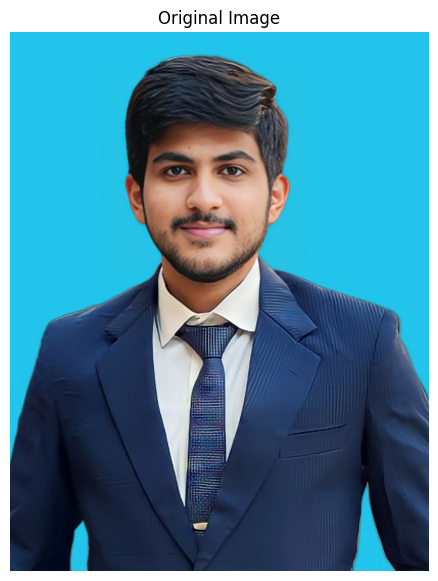

In [5]:
uploaded = files.upload()

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

print("Uploaded image:", image_path)
print("Image dimensions:", image.size)

plt.figure(figsize=(10, 7))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

Objects detected: 2


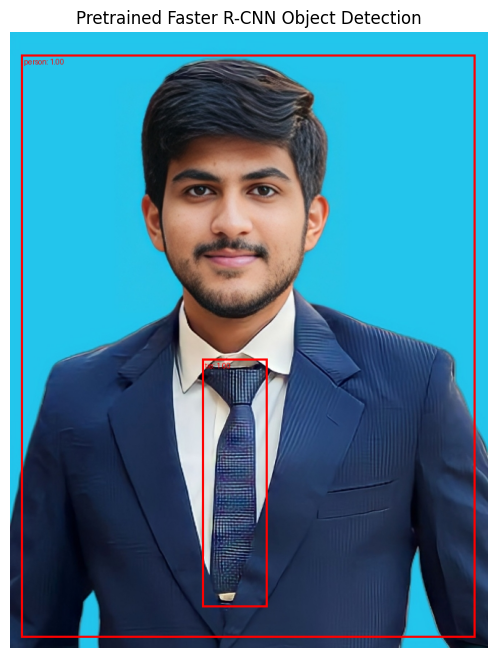

In [6]:
predictions = detect_objects(
    image=image,
    model=model,
    threshold=0.5
)

display_detections(
    image=image,
    predictions=predictions,
    class_names=class_names
)

In [7]:
print("DETECTION RESULTS")
print("-" * 50)

for i, (box, label, score) in enumerate(
    zip(
        predictions["boxes"],
        predictions["labels"],
        predictions["scores"]
    )
):
    print(f"Detection {i+1}")
    print("Class:", class_names[label.item()])
    print("Confidence:", round(score.item(), 4))
    print("Bounding Box:", box.tolist())
    print("-" * 50)

DETECTION RESULTS
--------------------------------------------------
Detection 1
Class: person
Confidence: 0.9998
Bounding Box: [15.283699035644531, 31.27838134765625, 642.4110107421875, 836.3320922851562]
--------------------------------------------------
Detection 2
Class: tie
Confidence: 0.9996
Bounding Box: [265.5703125, 451.4194641113281, 355.7608642578125, 794.8641967773438]
--------------------------------------------------


# Task 2: Compare Pretrained Object Detection Models

In [8]:
import time
import gc
import pandas as pd

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    fasterrcnn_resnet50_fpn_v2,
    fasterrcnn_mobilenet_v3_large_fpn,
    FasterRCNN_ResNet50_FPN_Weights,
    FasterRCNN_ResNet50_FPN_V2_Weights,
    FasterRCNN_MobileNet_V3_Large_FPN_Weights
)

model_configs = {
    "Faster R-CNN ResNet50-FPN": (
        fasterrcnn_resnet50_fpn,
        FasterRCNN_ResNet50_FPN_Weights.DEFAULT
    ),

    "Faster R-CNN MobileNetV3-FPN": (
        fasterrcnn_mobilenet_v3_large_fpn,
        FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
    ),

    "Faster R-CNN ResNet50-FPN V2": (
        fasterrcnn_resnet50_fpn_v2,
        FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    )
}

print("Models configured:", len(model_configs))

Models configured: 3


In [9]:
def compare_pretrained_models(
    image,
    model_configs,
    threshold=0.5
):

    comparison_results = []
    all_predictions = {}

    image_tensor = F.to_tensor(image).to(device)

    for model_name, (model_fn, weights) in model_configs.items():

        print("\n" + "=" * 60)
        print("Evaluating:", model_name)
        print("=" * 60)

        # Load pretrained model
        current_model = model_fn(
            weights=weights
        ).to(device)

        current_model.eval()

        # Count parameters
        parameters = sum(
            p.numel()
            for p in current_model.parameters()
        )

        # Warm-up inference
        with torch.no_grad():
            _ = current_model([image_tensor])

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        with torch.no_grad():
            output = current_model([image_tensor])[0]

        if device.type == "cuda":
            torch.cuda.synchronize()

        inference_time = time.perf_counter() - start_time

        # Move predictions to CPU
        output = {
            k: v.cpu()
            for k, v in output.items()
        }

        keep = output["scores"] >= threshold

        predictions = {
            "boxes": output["boxes"][keep],
            "labels": output["labels"][keep],
            "scores": output["scores"][keep]
        }

        all_predictions[model_name] = {
            "predictions": predictions,
            "categories": weights.meta["categories"]
        }

        detected_classes = [
            weights.meta["categories"][label.item()]
            for label in predictions["labels"]
        ]

        print("Detected objects:", len(predictions["boxes"]))
        print("Classes:", detected_classes)
        print(f"Inference time: {inference_time:.4f} seconds")

        comparison_results.append({
            "Model": model_name,
            "Parameters (M)": round(parameters / 1e6, 2),
            "Detections": len(predictions["boxes"]),
            "Inference Time (s)": round(inference_time, 4),
            "Mean Confidence": (
                round(predictions["scores"].mean().item(), 4)
                if len(predictions["scores"]) > 0 else 0
            )
        })

        # Free model memory
        del current_model
        gc.collect()

        if device.type == "cuda":
            torch.cuda.empty_cache()

    return pd.DataFrame(comparison_results), all_predictions

In [10]:
comparison_df, all_predictions = compare_pretrained_models(
    image=image,
    model_configs=model_configs,
    threshold=0.5
)

print("\nFINAL MODEL COMPARISON")

display(comparison_df)


Evaluating: Faster R-CNN ResNet50-FPN
Detected objects: 2
Classes: ['person', 'tie']
Inference time: 0.1326 seconds

Evaluating: Faster R-CNN MobileNetV3-FPN
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 185MB/s]


Detected objects: 2
Classes: ['person', 'tie']
Inference time: 0.0245 seconds

Evaluating: Faster R-CNN ResNet50-FPN V2
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 163MB/s]


Detected objects: 2
Classes: ['person', 'tie']
Inference time: 0.1503 seconds

FINAL MODEL COMPARISON


,Model,Parameters (M),Detections,Inference Time (s),Mean Confidence
0,Faster R-CNN ResNet50-FPN,41.76,2,0.1326,0.9997
1,Faster R-CNN MobileNetV3-FPN,19.39,2,0.0245,0.9985
2,Faster R-CNN ResNet50-FPN V2,43.71,2,0.1503,0.9984



Model: Faster R-CNN ResNet50-FPN
Objects detected: 2


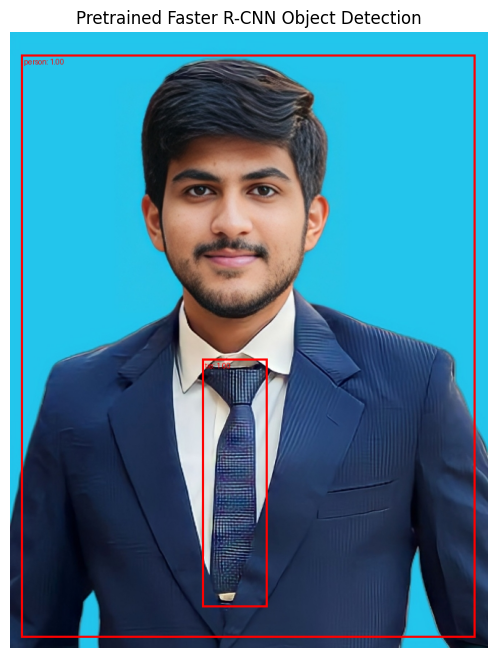


Model: Faster R-CNN MobileNetV3-FPN
Objects detected: 2


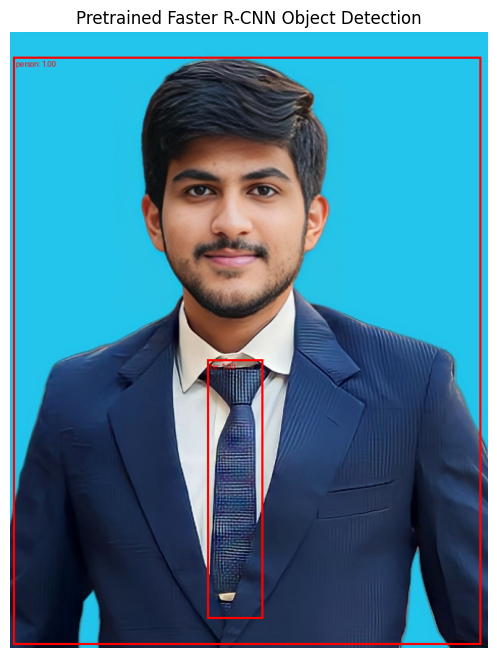


Model: Faster R-CNN ResNet50-FPN V2
Objects detected: 2


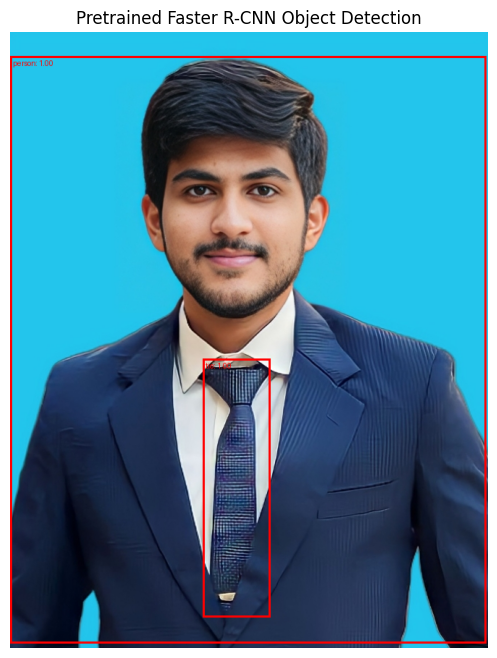

In [11]:
for model_name, result in all_predictions.items():

    print("\nModel:", model_name)

    display_detections(
        image=image,
        predictions=result["predictions"],
        class_names=result["categories"]
    )

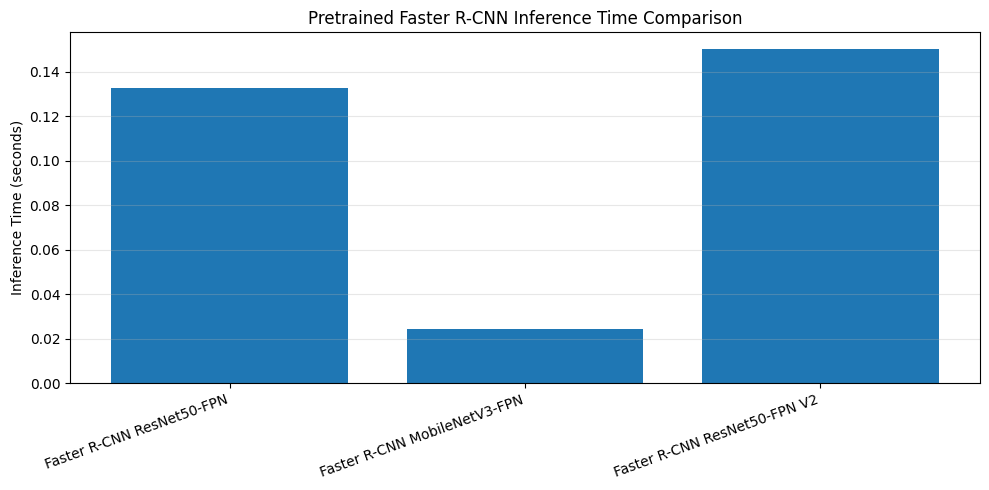

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Inference Time (s)"]
)

plt.ylabel("Inference Time (seconds)")
plt.title("Pretrained Faster R-CNN Inference Time Comparison")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

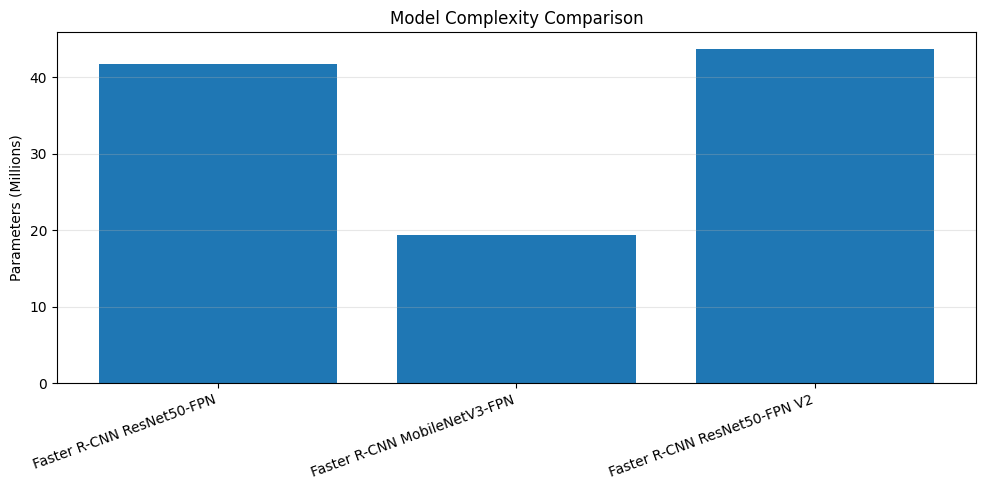

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Parameters (M)"]
)

plt.ylabel("Parameters (Millions)")
plt.title("Model Complexity Comparison")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Analysis
All three models successfully detected two objects: a person and a tie.

The MobileNetV3-FPN model contained significantly fewer parameters and achieved the lowest inference time of 0.0245 seconds.

The original ResNet50-FPN model required 0.1326 seconds, while ResNet50-FPN V2 required 0.1503 seconds.

Although ResNet50-FPN achieved the highest mean confidence, the differences in confidence scores were small. Higher confidence does not necessarily indicate better detection accuracy.

The results indicate that MobileNetV3-FPN offers an efficient alternative for object detection when computational resources and inference speed are important.

However, the inference times represent individual measured passes and may vary depending on the hardware and execution conditions.

# Task 3: Evaluate Pretrained Faster R-CNN Models Using mAP

In [14]:
from google.colab import files
import os
import zipfile

uploaded = files.upload()

zip_filename = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

extract_dir = "/content/tutorial8a_data"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

dataset_root = os.path.join(
    extract_dir, "BottleDataset"
)

images_dir = os.path.join(dataset_root, "images")
labels_dir = os.path.join(dataset_root, "labels")

print("Images:", len(os.listdir(images_dir)))
print("Annotations:", len(os.listdir(labels_dir)))

Saving BottleDataset_150_Clean.zip to BottleDataset_150_Clean.zip
Images: 150
Annotations: 150


In [16]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from pathlib import Path
from PIL import Image

# Determine the correct COCO bottle class
coco_classes = (
    FasterRCNN_ResNet50_FPN_Weights.DEFAULT
    .meta["categories"]
)

BOTTLE_CLASS_ID = coco_classes.index("bottle")

print("COCO Bottle Class ID:", BOTTLE_CLASS_ID)


class BottleEvaluationDataset(Dataset):

    def __init__(self, images_dir, labels_dir):

        self.images_dir = Path(images_dir)
        self.labels_dir = Path(labels_dir)

        self.images = sorted([
            p for p in self.images_dir.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ])

        if not self.images:
            raise ValueError("No images found")

        for path in self.images:
            label_path = self.labels_dir / (path.stem + ".txt")

            if not label_path.exists():
                raise FileNotFoundError(label_path)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_path = self.images[idx]
        label_path = self.labels_dir / (image_path.stem + ".txt")

        image = Image.open(image_path).convert("RGB")

        width, height = image.size

        boxes = []
        labels = []

        with open(label_path, "r") as f:

            for line in f:

                if not line.strip():
                    continue

                values = list(map(float, line.split()))

                if len(values) != 5:
                    raise ValueError(
                        f"Invalid YOLO label in {label_path}"
                    )

                cls, xc, yc, bw, bh = values

                if int(cls) != 0:
                    raise ValueError(
                        "Expected one YOLO class: bottle (0)"
                    )

                # Convert YOLO -> xyxy
                x1 = (xc - bw / 2) * width
                y1 = (yc - bh / 2) * height
                x2 = (xc + bw / 2) * width
                y2 = (yc + bh / 2) * height

                x1 = max(0.0, min(float(width), x1))
                y1 = max(0.0, min(float(height), y1))
                x2 = max(0.0, min(float(width), x2))
                y2 = max(0.0, min(float(height), y2))

                if x2 <= x1 or y2 <= y1:
                    raise ValueError(
                        f"Invalid box in {label_path}"
                    )

                boxes.append([x1, y1, x2, y2])

                labels.append(BOTTLE_CLASS_ID)

        target = {
            "boxes": torch.tensor(
                boxes, dtype=torch.float32
            ).reshape(-1, 4),

            "labels": torch.tensor(
                labels, dtype=torch.int64
            )
        }

        return TF.to_tensor(image), target


evaluation_dataset = BottleEvaluationDataset(
    images_dir,
    labels_dir
)

print("Total evaluation images:", len(evaluation_dataset))

COCO Bottle Class ID: 44
Total evaluation images: 150


In [17]:
def evaluation_collate_fn(batch):
    return tuple(zip(*batch))


evaluation_loader = DataLoader(
    evaluation_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=evaluation_collate_fn,
    num_workers=2
)

image, target = evaluation_dataset[0]

print("Image shape:", image.shape)
print("Bounding boxes:", target["boxes"].shape)
print("Labels:", target["labels"])

Image shape: torch.Size([3, 640, 640])
Bounding boxes: torch.Size([1, 4])
Labels: tensor([44])


In [18]:
!pip -q install torchmetrics pycocotools

In [19]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision
import time

def evaluate_pretrained_detector(model, data_loader):

    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    total_images = 0
    total_inference_time = 0.0

    with torch.inference_mode():

        for images, targets in data_loader:

            images_gpu = [
                image.to(device) for image in images
            ]

            if device.type == "cuda":
                torch.cuda.synchronize()

            start_time = time.perf_counter()

            outputs = model(images_gpu)

            if device.type == "cuda":
                torch.cuda.synchronize()

            total_inference_time += (
                time.perf_counter() - start_time
            )

            # Keep only bottle detections
            predictions = []

            for output in outputs:

                output = {
                    k: v.cpu()
                    for k, v in output.items()
                }

                keep = (
                    output["labels"] == BOTTLE_CLASS_ID
                )

                predictions.append({
                    "boxes": output["boxes"][keep],
                    "scores": output["scores"][keep],
                    "labels": output["labels"][keep]
                })

            ground_truths = [
                {
                    "boxes": target["boxes"].cpu(),
                    "labels": target["labels"].cpu()
                }
                for target in targets
            ]

            metric.update(predictions, ground_truths)

            total_images += len(images)

    results = metric.compute()

    return {
        "mAP@0.5": results["map_50"].item(),
        "mAP@0.5:0.95": results["map"].item(),
        "Average Inference Time (s)": (
            total_inference_time / total_images
        )
    }

In [20]:
import gc
import pandas as pd

# Remove the original model from memory if it exists
if "model" in globals():
    del model

gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()


evaluation_results = []

for model_name, (model_fn, weights) in model_configs.items():

    print("\n" + "=" * 55)
    print("Evaluating:", model_name)
    print("=" * 55)

    current_model = model_fn(
        weights=weights
    ).to(device)

    current_model.eval()

    metrics = evaluate_pretrained_detector(
        current_model,
        evaluation_loader
    )

    print(f"mAP@0.5: {metrics['mAP@0.5']:.4f}")
    print(
        f"mAP@0.5:0.95: "
        f"{metrics['mAP@0.5:0.95']:.4f}"
    )

    evaluation_results.append({
        "Model": model_name,
        **metrics
    })

    del current_model

    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()


map_comparison_df = pd.DataFrame(evaluation_results)

print("\nFINAL mAP COMPARISON")
display(map_comparison_df)


Evaluating: Faster R-CNN ResNet50-FPN
mAP@0.5: 0.9597
mAP@0.5:0.95: 0.8100

Evaluating: Faster R-CNN MobileNetV3-FPN
mAP@0.5: 0.9795
mAP@0.5:0.95: 0.7967

Evaluating: Faster R-CNN ResNet50-FPN V2
mAP@0.5: 0.9799
mAP@0.5:0.95: 0.8745

FINAL mAP COMPARISON


,Model,mAP@0.5,mAP@0.5:0.95,Average Inference Time (s)
0,Faster R-CNN ResNet50-FPN,0.959702,0.810014,0.104821
1,Faster R-CNN MobileNetV3-FPN,0.979491,0.796666,0.019956
2,Faster R-CNN ResNet50-FPN V2,0.979877,0.874521,0.152273


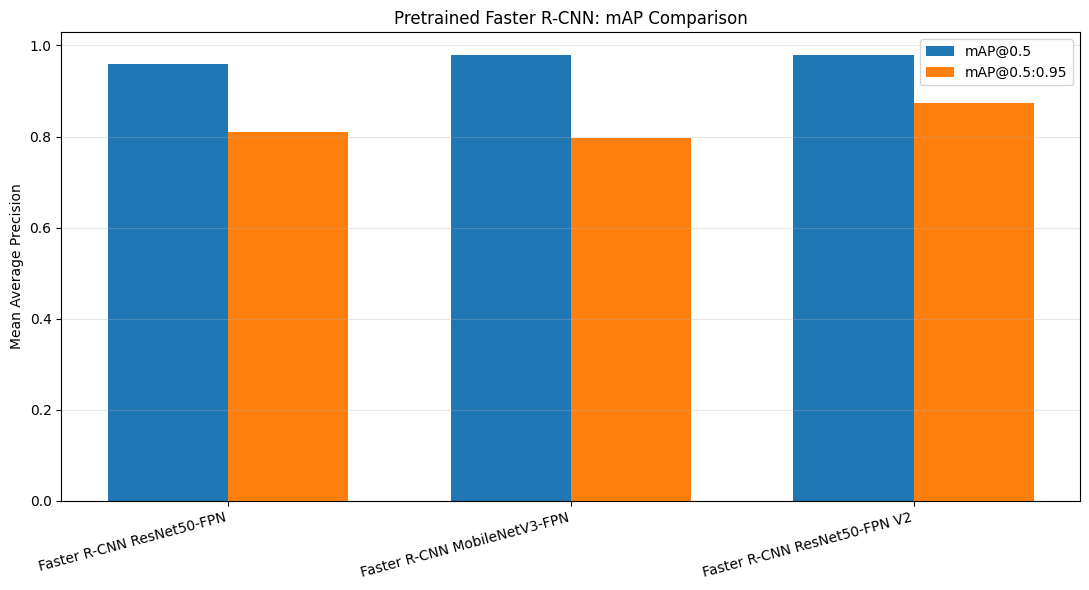

In [21]:
import matplotlib.pyplot as plt
import numpy as np

models = map_comparison_df["Model"]

map50 = map_comparison_df["mAP@0.5"]
map5095 = map_comparison_df["mAP@0.5:0.95"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width/2,
    map50,
    width,
    label="mAP@0.5"
)

plt.bar(
    x + width/2,
    map5095,
    width,
    label="mAP@0.5:0.95"
)

plt.xticks(
    x,
    models,
    rotation=15,
    ha="right"
)

plt.ylabel("Mean Average Precision")
plt.title("Pretrained Faster R-CNN: mAP Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

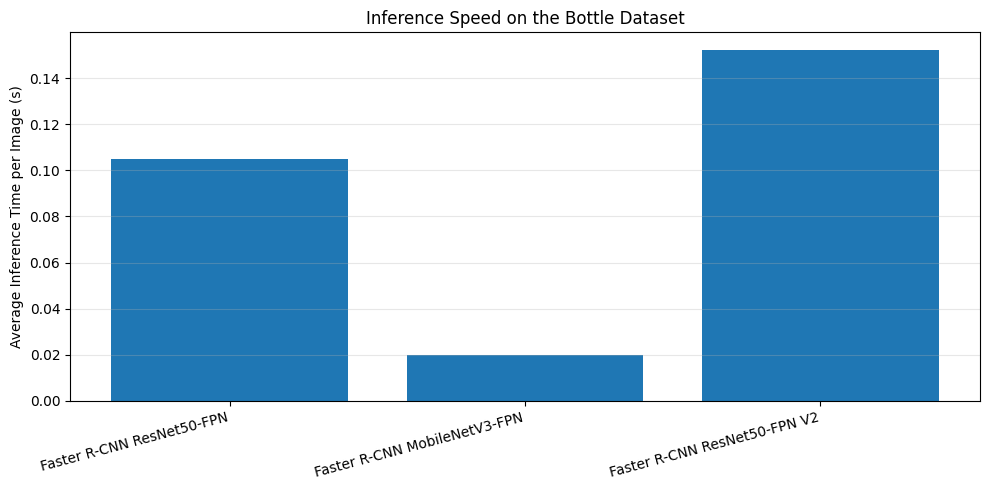

In [22]:
plt.figure(figsize=(10, 5))

plt.bar(
    map_comparison_df["Model"],
    map_comparison_df["Average Inference Time (s)"]
)

plt.ylabel("Average Inference Time per Image (s)")
plt.title("Inference Speed on the Bottle Dataset")

plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Sample index: 28
Actual bottles: 1


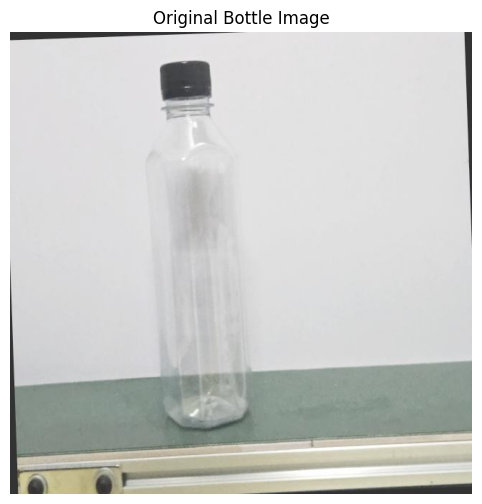


Model: Faster R-CNN ResNet50-FPN
Detected bottles: 1
Objects detected: 1


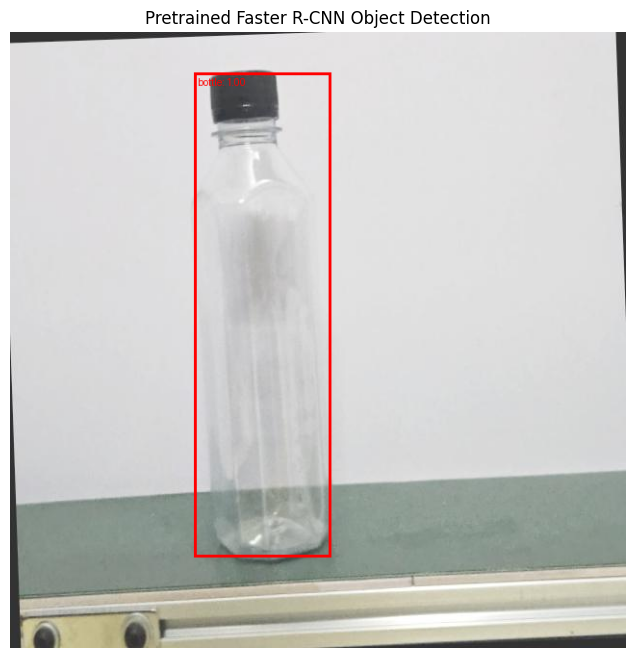


Model: Faster R-CNN MobileNetV3-FPN
Detected bottles: 1
Objects detected: 1


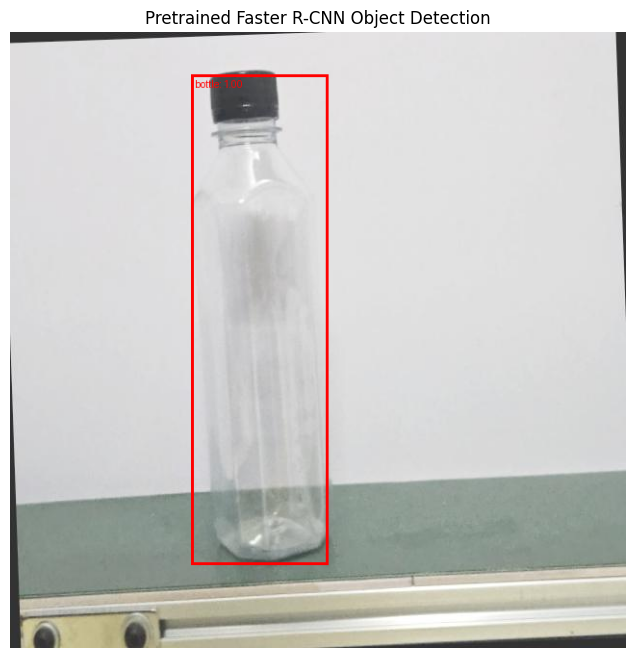


Model: Faster R-CNN ResNet50-FPN V2
Detected bottles: 1
Objects detected: 1


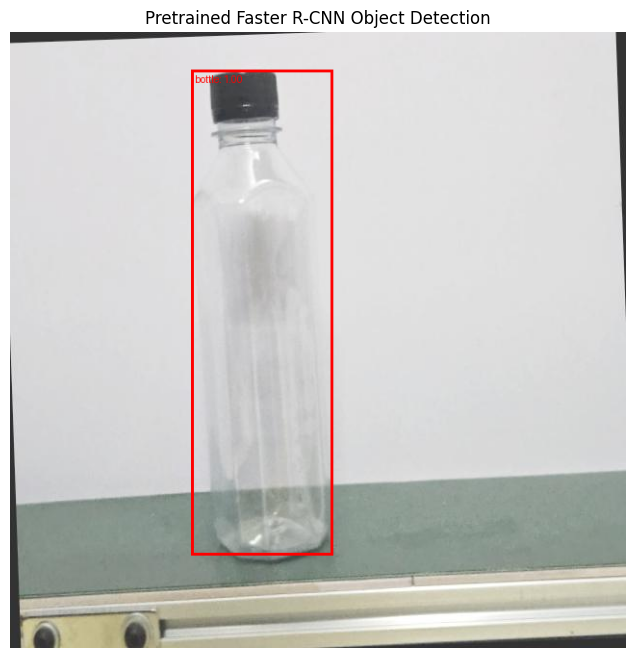

In [23]:
import random

random.seed(42)

sample_idx = random.randrange(len(evaluation_dataset))

sample_image, sample_target = evaluation_dataset[sample_idx]

print("Sample index:", sample_idx)
print("Actual bottles:", len(sample_target["boxes"]))

# Show original image
plt.figure(figsize=(8, 6))
plt.imshow(F.to_pil_image(sample_image))
plt.title("Original Bottle Image")
plt.axis("off")
plt.show()


for model_name, (model_fn, weights) in model_configs.items():

    current_model = model_fn(
        weights=weights
    ).to(device)

    current_model.eval()

    with torch.inference_mode():
        output = current_model(
            [sample_image.to(device)]
        )[0]

    output = {
        k: v.cpu() for k, v in output.items()
    }

    keep = (
        (output["labels"] == BOTTLE_CLASS_ID) &
        (output["scores"] >= 0.3)
    )

    bottle_predictions = {
        "boxes": output["boxes"][keep],
        "labels": output["labels"][keep],
        "scores": output["scores"][keep]
    }

    print("\nModel:", model_name)
    print("Detected bottles:", keep.sum().item())

    display_detections(
        image=F.to_pil_image(sample_image),
        predictions=bottle_predictions,
        class_names=weights.meta["categories"]
    )

    del current_model
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

In [24]:
import os

save_dir = "/content/tutorial8a_results"

os.makedirs(save_dir, exist_ok=True)

map_comparison_df.to_csv(
    f"{save_dir}/pretrained_model_map_comparison.csv",
    index=False
)

display(map_comparison_df)

print("Evaluation results saved successfully.")

,Model,mAP@0.5,mAP@0.5:0.95,Average Inference Time (s)
0,Faster R-CNN ResNet50-FPN,0.959702,0.810014,0.104821
1,Faster R-CNN MobileNetV3-FPN,0.979491,0.796666,0.019956
2,Faster R-CNN ResNet50-FPN V2,0.979877,0.874521,0.152273


Evaluation results saved successfully.


## Analysis
All three pretrained models achieved high mAP@0.5 values, indicating successful bottle detection and localization at an IoU threshold of 0.5.

ResNet50-FPN V2 achieved the highest mAP@0.5:0.95 of 87.45%, demonstrating the best localization performance across the evaluated IoU thresholds.

MobileNetV3-FPN achieved the fastest average inference time of approximately 0.0200 seconds per image. However, it achieved the lowest mAP@0.5:0.95 among the three models.

The original ResNet50-FPN achieved 81.00% mAP@0.5:0.95, offering an intermediate result in terms of detection accuracy and inference speed.

Visual testing on a randomly selected image showed that all three models detected the annotated bottle.